# Injected edges vs. MST: between-cluster edges and speciation time

Two `AdaptiveKNNGraph` construction modes, same pipeline and same `log_scale_and_shift`
normalization, swept over `n_samples` at **D = 1024** (the runs on disk also cover D=256 and
D=4096; only D=1024 is loaded here):

| mode | directory | pipeline flags |
| --- | --- | --- |
| `injected` | `data/injected/` | `--inject_edges` (random extra edges), `--clipping` |
| `mst` | `data/mst/` | MST-based connectivity instead of injected edges |

Three things below: the SAGD distance matrices for every available `n_samples` in both modes,
and -- for the largest run -- the animated per-snapshot distributions, which show the
between-cluster kNN edges (the graph *cut*) alongside the normalized-CTD and Euclidean-distance
histograms.

The animation helpers come from `lib.viz.dist_animation`, extracted from
`speciation_time_nsweep.ipynb` so both notebooks can animate the same run outputs; the only
change is that the run (`cell`, `run_dir`) is passed in explicitly instead of being looked up in
that notebook's globals, plus a `label` for the figure title.

In [3]:
import re
from pathlib import Path

import joblib
import numpy as np
import matplotlib.pyplot as plt

from lib.ou_model import find_third_phase_onset
from lib.viz.plotting import _draw_sagd_heatmap_with_prob
from lib.viz.dist_animation import animate_distributions

## Load

One entry per `(mode, n_samples)`, holding the SAGD distance matrix, the snapshot times, and the
two regime-boundary times drawn on the heatmaps: `tsagd` (first DP breakpoint from
`clusters.jbl`) and `tstar` (`find_third_phase_onset` on the CTD distributions). `history.jbl`
is deliberately not touched here -- it is ~1-3 GB per run and only the animation needs it.

In [4]:
DATA_ROOT = Path("../data")
MODES = ["injected", "mst"]
D = 1024
T = 10.0
MU = 4.0
STD = 1.0

RUN_PATTERN = re.compile(rf"^D(\d+)_N(\d+)_T{int(T)}$")
REQUIRED_FILES = ["Ws.jbl", "CTDs.jbl", "SAGD.jbl", "clusters.jbl"]


def discover_runs(mode_root, d):
    """`n_samples -> run_dir` for every finished `d`-dimensional run under one mode directory.

    Each experiment directory holds one `D{d}_N{n}_T{T}` subdirectory per swept dimension, so
    the dimension is read off the run directory rather than the experiment name.
    """
    found = {}
    for exp_dir in sorted(p for p in mode_root.iterdir() if p.is_dir()):
        for run_dir in sorted(p for p in exp_dir.iterdir() if p.is_dir()):
            m = RUN_PATTERN.match(run_dir.name)
            if not m or int(m.group(1)) != d:
                continue
            missing = [f for f in REQUIRED_FILES if not (run_dir / f).exists()]
            if missing:
                print(f"Skipping {run_dir}: run not finished (missing {missing})")
                continue
            found[int(m.group(2))] = run_dir
    return found


def load_run(run_dir):
    """SAGD matrix, snapshot times and regime boundaries for one run directory."""
    breakpoints = joblib.load(run_dir / "clusters.jbl")
    ctds = joblib.load(run_dir / "CTDs.jbl")
    snaps = np.asarray(ctds["params"]["ts"])
    return dict(
        W=joblib.load(run_dir / "SAGD.jbl"),
        time_snaps=snaps,
        ts=None,
        tsagd=snaps[breakpoints[0]],
        tstar=find_third_phase_onset(ctds["CTDs"], snaps),
        ctds=ctds,
        mu=MU,
    )


run_dirs = {mode: discover_runs(DATA_ROOT / mode, D) for mode in MODES}
n_list = sorted({n for mode in MODES for n in run_dirs[mode]})
runs = {(mode, n): load_run(run_dirs[mode][n])
        for mode in MODES for n in n_list if n in run_dirs[mode]}

for (mode, n), cell in runs.items():
    print(f"{mode:>8}  N={n:<5}  t_sagd={cell['tsagd']:.2f}  t*={cell['tstar']:.2f}  "
          f"{len(cell['time_snaps'])} snapshots")

injected  N=1000   t_sagd=3.06  t*=1.35  233 snapshots
injected  N=2000   t_sagd=3.09  t*=1.20  233 snapshots
injected  N=4000   t_sagd=3.03  t*=1.02  233 snapshots
     mst  N=1000   t_sagd=2.94  t*=1.38  233 snapshots
     mst  N=2000   t_sagd=2.97  t*=1.08  233 snapshots
     mst  N=4000   t_sagd=2.94  t*=0.96  233 snapshots


## SAGD distance matrices

Columns are the graph-construction mode, rows are `n_samples`; a `(mode, n)` combination that is
not on disk is left blank. Each cell is `_draw_sagd_heatmap_with_prob`: the SAGD matrix itself
(percentile-clipped to [5%, 95%] and rescaled to [0, 1], so the two modes share a colour scale
even though their raw SAGD ranges differ), with the mean and variance of the normalized CTD
distribution underneath and the detected `t_SAGD` / `t*_SAGD` boundaries marked on both.

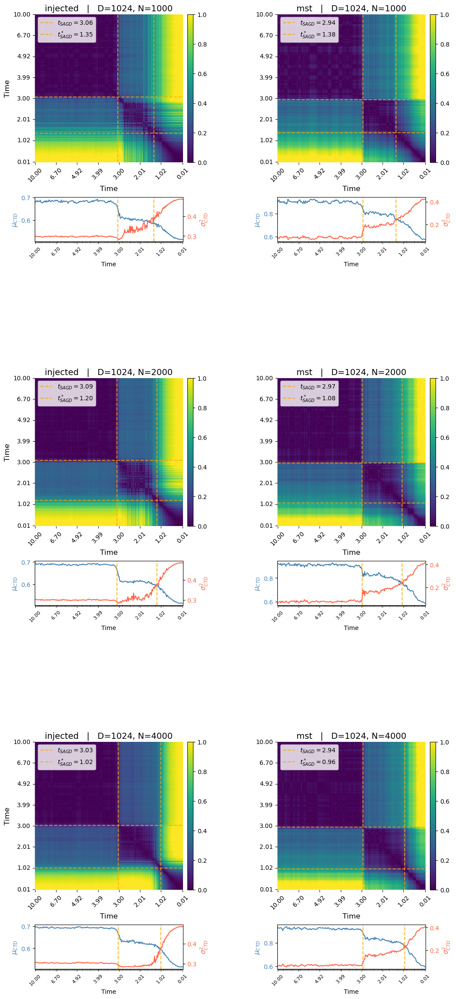

In [13]:
def plot_sagd_mode_grid(runs, modes, n_list, d, std, clipping=True, save_fig_path=None):
    """Grid of SAGD distance matrices: columns = construction mode, rows = `n_samples`.

    `runs` maps `(mode, n_samples)` to a `load_run` entry; missing combinations are left blank.
    """
    fig, axes = plt.subplots(
        nrows=len(n_list), ncols=len(modes),
        figsize=(6 * len(modes), 9.5 * len(n_list)),
        gridspec_kw={"wspace": 0.5, "hspace": 0.6},
        squeeze=False,
    )

    for row, n in enumerate(n_list):
        for col, mode in enumerate(modes):
            ax = axes[row, col]
            cell = runs.get((mode, n))
            if cell is None:
                ax.axis("off")
                ax.text(0.5, 0.5, f"{mode}, N={n}\n(no data)", ha="center", va="center",
                        fontsize=11, color="gray", transform=ax.transAxes)
                continue

            _draw_sagd_heatmap_with_prob(
                ax_hm=ax,
                W=cell["W"],
                time_vector=cell["time_snaps"],
                d=d,
                mu=cell["mu"],
                std=std,
                ts=cell["ts"],
                tsagd=cell["tsagd"],
                t_star=cell["tstar"],
                show_ylabel=(col == 0),
                show_legend=True,
                show_prob=False,
                distance="SAGD",
                ctds=cell["ctds"],
                model="synthetic",
                clipping=clipping,
            )
            ax.set_title(f"{mode}   |   D={d}, N={n}", fontsize=14)

    if save_fig_path:
        Path(save_fig_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_fig_path, dpi=200, bbox_inches="tight")
    plt.show()


plot_sagd_mode_grid(runs, MODES, n_list, D, STD,
                    save_fig_path=f"figs/sagd_injected_vs_mst_D{D}.png")

## Animated distributions

Per-snapshot player for the **N = 4000** run of each mode, over `t = 5 -> 0.5` (the window around
the transition). Three panels per frame:

1. the analytic bimodal mixture at that time, projected on the mean-difference plane, overlaid
   with this run's own samples and the kNN edges that *join the two clusters* -- the between-cluster
   cut, reported both as an edge count and as a weight fraction of the whole graph;
2. the normalized CTD distribution (what the SAGD Wasserstein distance compares);
3. the pairwise Euclidean-distance distribution.

The cut counts in panel 1 are the direct comparison between the two modes: injection adds random
long-range edges, the MST fallback adds only the edges needed to connect the graph.

The first call for a run builds `euclid_dists.jbl` and `proj2d.jbl` next to the other pipeline
outputs (reading the large `history.jbl` and `Ws.jbl` once); later calls read only those caches.

In [14]:
ANIM_N = 4000
T_RANGE = (0, 5.0)

animate_distributions(
    runs[("injected", ANIM_N)], run_dirs["injected"][ANIM_N],
    d=D, n=ANIM_N, std=STD, label="injected", t_range=T_RANGE,
    save_path=f"figs/dist_animation_injected_D{D}_N{ANIM_N}.html",
)

Saved animation -> figs/dist_animation_injected_D1024_N4000.html


In [17]:
animate_distributions(
    runs[("mst", ANIM_N)], run_dirs["mst"][ANIM_N],
    d=D, n=ANIM_N, std=STD, label="mst", t_range=T_RANGE, coverage=1.0,
    save_path=f"figs/dist_animation_mst_D{D}_N{ANIM_N}.html",
)

Saved animation -> figs/dist_animation_mst_D1024_N4000.html


In [19]:
animate_distributions(
    runs[("mst", 1000)], run_dirs["mst"][1000],
    d=D, n=1000, std=STD, label="mst", t_range=T_RANGE, coverage=1.0,
    save_path=f"figs/dist_animation_mst_D{D}_N{1000}.html",
)

Saved animation -> figs/dist_animation_mst_D1024_N1000.html


## Cut weight vs. CTD peak distance

The same two quantities the animation shows frame by frame, plotted against time: the
between-cluster cut as a fraction of the graph's total edge weight (left axis, `proj2d.jbl`)
and the gap between the two highest peaks of the normalized CTD distribution (right axis,
`ctd_peak_separation`). Both ask when the graph stops mixing the two clusters, so the question
is whether they turn over together -- and whether that differs between the two construction
modes: injection keeps random long-range edges across the cut, the MST fallback keeps only the
bridges needed for connectivity.

One figure per mode, for the same `N = 4000` runs and time window as the animations above, so
`get_projection_and_cut` reads the `proj2d.jbl` those cells already built.

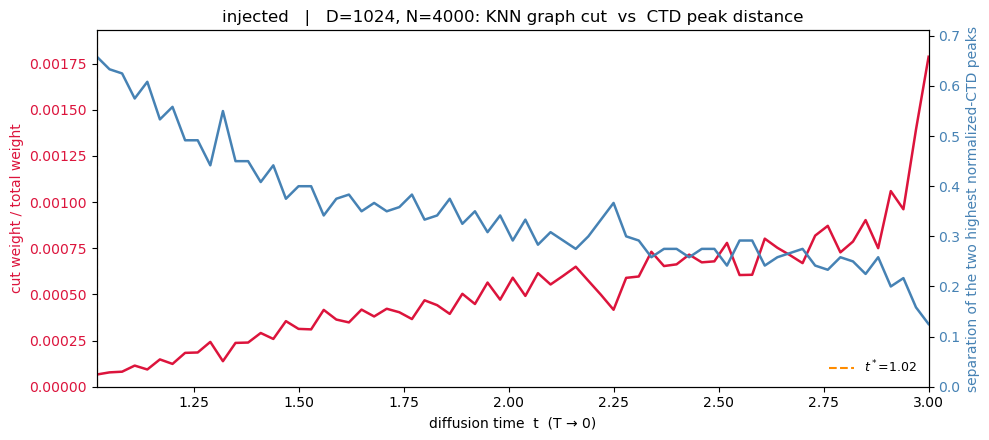

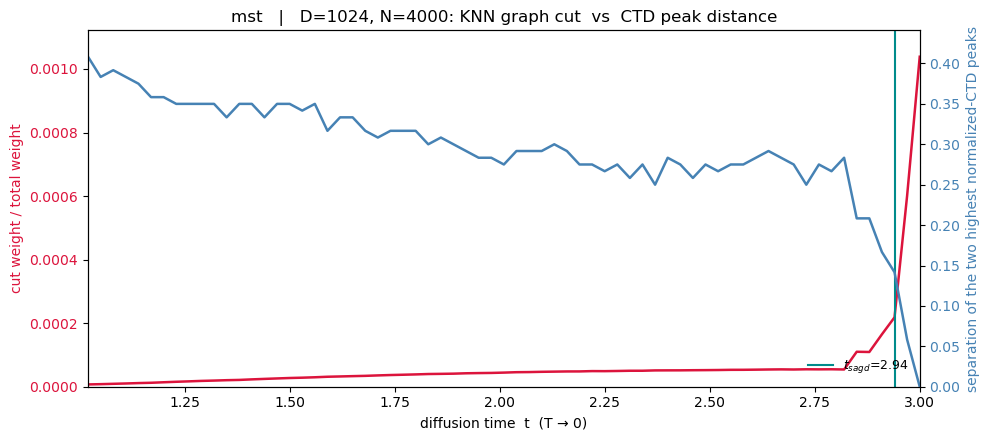

In [9]:
from lib.viz.cut_peaks import plot_cut_and_ctd_peaks

for mode in MODES:
    plot_cut_and_ctd_peaks(
        runs[(mode, ANIM_N)], run_dirs[mode][ANIM_N],
        d=D, n=ANIM_N, std=STD, label=mode, t_range=[1, 3],
        save_fig_path=f"figs/cut_vs_ctd_peaks_{mode}_D{D}_N{ANIM_N}.png",
    )
plt.show()

# What produces the peaks in the noise-stage CTD distribution

The peaks are a **vertex-degree** effect. Above the transition the samples are isotropic Gaussian
noise, so the kNN graph has no geometry left to exploit and commute times collapse to the
large-graph limit of von Luxburg et al., *Hitting and commute times in large graphs are often
misleading*:

$$\mathrm{CTD}(i, j) \;\approx\; \mathrm{vol}(G)\left(\frac{1}{d_i} + \frac{1}{d_j}\right),
\qquad d_i = \sum_j W_{ij}, \quad \mathrm{vol}(G) = \sum_i d_i .$$

The commute time forgets the pair and keeps only the two endpoint degrees. In a kNN graph those
degrees are near-discrete -- integer neighbour counts times an almost constant edge weight -- so
a near-discrete predictor produces a near-discrete CTD: one peak per degree class
$(d_i, d_j)$.

Note the constant: the relation above has slope exactly $\mathrm{vol}(G)$ and **no** intercept.
It is an identity, not a calibrated fit -- it is what the spectral formula for the commute time
reduces to when every non-trivial eigenvalue of the normalized Laplacian equals 1. Everything
below is plotted against that theoretical value directly, with no fitted constant, so the
deviations are visible rather than absorbed.

This section uses `data/mst_raw_ctds/` -- the only run with `--keep_raw_ctds`, whose CTD arrays are
still indexed by vertex pair rather than compressed to quantiles -- at **D = 1024, N = 1000**, and
looks at three snapshots: `t = 10` and `t = 5` (noise stage, above `t_sagd ≈ 3.09`) and `t = 1`
(well after speciation).

## Load the raw-CTD run

`CTDs.jbl` here stores the full `C[np.triu_indices(N, 1)]` vector per snapshot instead of 5000
equal-frequency quantiles, and that ordering is what lets a CTD value be traced back to its
vertex pair and hence to the endpoint degrees. `history.jbl` supplies the sample positions, used
both for the pairwise distances and for the cluster labels that split pairs into within- and
between-cluster. This cell loads ~4 GB.

In [6]:
from scipy.spatial.distance import pdist

RAW_N = 1000
TIMES = (10.0, 5.0, 1.0)

raw_dir = discover_runs(DATA_ROOT / "mst_raw_ctds", D)[RAW_N]
raw_graphs = joblib.load(raw_dir / "Ws.jbl")
raw_ctds = joblib.load(raw_dir / "CTDs.jbl")["CTDs"]
raw_hist = joblib.load(raw_dir / "history.jbl")["history"]
raw_ts = np.asarray(raw_graphs["ts"])
raw_tsagd = float(raw_ts[joblib.load(raw_dir / "clusters.jbl")[0]])
IU, JU = np.triu_indices(RAW_N, k=1)
MU_DIR = np.full(D, MU) / np.linalg.norm(np.full(D, MU))


def snapshot(t_target):
    """Everything one snapshot contributes to this section, nearest `t_target`.

    `ctd` is `C[np.triu_indices(N, 1)]` as written by `utils.ctd_job`, so pair `p` is the vertex
    pair `(IU[p], JU[p])`; `pdist` on `points` uses that same ordering, and so does `between`.
    A point's cluster is the sign of its coordinate along the mean-difference direction.
    `deg_class` is what `plot_ctd_vs_degrees` groups pairs by -- the unweighted degree here, a
    binned weighted degree for the dense graphs of section 4 -- and `class_title` names it.
    """
    i = int(np.argmin(np.abs(raw_ts - t_target)))
    t = float(raw_ts[i])
    points = np.asarray(raw_hist[t], dtype=float)
    labels = np.sign(points @ MU_DIR)
    W = raw_graphs["Ws"][i]
    return {
        "t": t,
        "W": W,
        "sigma": float(np.asarray(raw_graphs["sigma"])[i]),
        "k": int(raw_graphs["ks"][i]),
        "points": points,
        "ctd": np.asarray(raw_ctds[t]["ctds"]),
        "between": labels[IU] != labels[JU],
        "deg_u": (W > 0).sum(1),
        "deg_w": W.sum(1),
        "vol": W.sum(),
        "deg_class": (W > 0).sum(1),
        "class_title": "$(d_i, d_j)$",
        "graph": "AdaptiveKNNGraph",
    }


def theoretical_ctd(snap):
    """`vol(G) * (1/d_i + 1/d_j)` for every vertex pair, in the `IU`/`JU` ordering."""
    d = snap["deg_w"]
    return snap["vol"] * (1.0 / d[IU] + 1.0 / d[JU])


def top_classes(values, n_top=10):
    """The `n_top` most frequent values, in ascending order, and the fraction each one holds.

    Returns `(values, fractions, other)`, where `other` is the pooled fraction of everything
    outside the top `n_top` -- the trailing merged bin of the histograms below.
    """
    vals, counts = np.unique(values, axis=0, return_counts=True)
    keep = np.argsort(counts)[::-1][:n_top]
    vals, counts = vals[keep], counts[keep]
    order = np.lexsort(vals.T[::-1]) if vals.ndim > 1 else np.argsort(vals)
    fractions = counts[order] / np.asarray(values).shape[0]
    return vals[order], fractions, 1.0 - fractions.sum()


snaps = {t: snapshot(t) for t in TIMES}
print(f"raw-CTD run: {raw_dir}")
print(f"{len(raw_ts)} snapshots, {len(snaps[TIMES[0]]['ctd'])} pairs each, t_sagd={raw_tsagd:.2f}")
for t, s in snaps.items():
    w = s["W"][s["W"] > 0]
    print(f"  t={s['t']:5.2f}  k={s['k']:2d}  sigma={s['sigma']:7.3f}  "
          f"edges={int((s['W'] > 0).sum() // 2):5d}  "
          f"edge weight {w.min():.3f}-{w.max():.3f} (cv {w.std() / w.mean():.1%})")

raw-CTD run: ../data/mst_raw_ctds/log_scale_and_shift_D256 1024 4096_n1000/D1024_N1000_T10
233 snapshots, 499500 pairs each, t_sagd=3.09
  t=10.00  k= 5  sigma= 42.919  edges= 4487  edge weight 0.583-0.635 (cv 1.3%)
  t= 5.01  k= 5  sigma= 43.001  edges= 4497  edge weight 0.584-0.641 (cv 1.3%)
  t= 0.99  k=15  sigma= 43.661  edges= 4379  edge weight 0.070-0.641 (cv 1.8%)


## 1. The kNN graph's edge weights

Why the graph is *effectively unweighted*. The kernel is $w = \exp(-r^2 / 2\sigma^2)$ with
$\sigma$ the median kNN distance (`AdaptiveKNNGraph.gaussian_kernel`), and `compute_W` keeps that
weight on exactly the edges the adjacency selects, so the only thing that matters is the spread
of the weights **of the edges actually in the graph** -- not that of the full pair population.

In $d = 1024$ the pairwise distances concentrate, so every kNN edge has length $\approx \sigma$
and weight $\approx e^{-1/2} \approx 0.607$: the histograms below sit in a narrow spike at that
value and the graph is a constant times its binary adjacency matrix. That matters because the
commute time is invariant under a global rescaling $W \to cW$ ($L \to cL$, $L^+ \to L^+/c$,
$\mathrm{vol} \to c\,\mathrm{vol}$), so a near-constant weight cancels exactly and the weighted
graph behaves like the unweighted one.

Edges are split by whether they join the two clusters, on a logarithmic count axis since the two
populations differ by orders of magnitude once the clusters separate. After speciation the
between-cluster edges are only the handful of bridges `connect_components` adds to keep the graph
connected -- a single one at `t = 1` -- and they sit far below the bulk (`w = 0.07` here, with
`compute_W` clipping at a `1e-6` floor). Being that few they cannot move the bulk: the
within-cluster weights stay at a 1.2% coefficient of variation, so the effectively-unweighted
regime survives to `t = 1`.

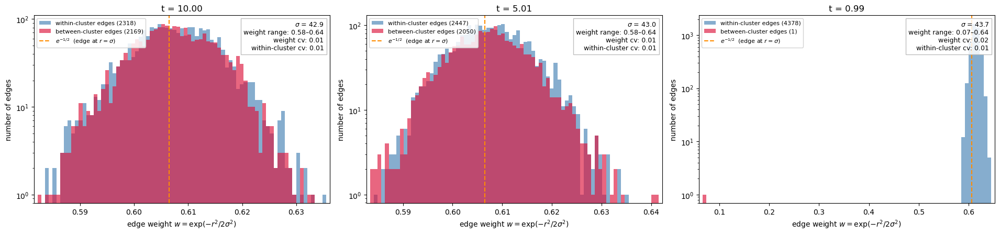

In [7]:
def plot_edge_weights(times=TIMES, bins=80, log_ratio=10.0, save_fig_path=None):
    """Distribution of the kNN graph's own edge weights, per snapshot.

    The weights are read off `W` itself rather than recomputed: `compute_W` writes
    `exp(-r^2 / 2 sigma^2)` (floored at 1e-6) on the selected edges with one global `sigma`, so
    the histogram is the graph's actual weighting. Within- and between-cluster edges are drawn
    separately on a logarithmic count axis, the bridge edges being several orders of magnitude
    rarer than the bulk. The x-axis turns logarithmic once the weights span more than
    `log_ratio`, which happens after speciation when the bridges reach the weight floor.
    """
    fig, axes = plt.subplots(1, len(times), figsize=(6.4 * len(times), 4.6))
    for ax, t_target in zip(np.atleast_1d(axes), times):
        s = snaps[t_target]
        ei, ej = np.triu(s["W"], 1).nonzero()
        w_edge = s["W"][ei, ej]
        labels = np.sign(s["points"] @ MU_DIR)
        cross = labels[ei] != labels[ej]

        logx = w_edge.max() / w_edge.min() > log_ratio
        if logx:
            edges = np.geomspace(w_edge.min() * 0.9, w_edge.max() * 1.1, bins)
            ax.set_xscale("log")
        else:
            lo, hi = w_edge.min(), w_edge.max()
            pad = 0.02 * (hi - lo) or 1e-3
            edges = np.linspace(lo - pad, hi + pad, bins)

        ax.hist(w_edge[~cross], bins=edges, color="steelblue", alpha=0.65,
                label=f"within-cluster edges ({int((~cross).sum())})")
        if cross.any():
            ax.hist(w_edge[cross], bins=edges, color="crimson", alpha=0.65,
                    label=f"between-cluster edges ({int(cross.sum())})")
        ax.axvline(np.exp(-0.5), color="darkorange", ls="--", lw=1.5,
                   label=r"$e^{-1/2}$  (edge at $r=\sigma$)")

        ax.set_yscale("log")
        ax.set_xlabel(r"edge weight $w = \exp(-r^2 / 2\sigma^2)$")
        ax.set_ylabel("number of edges")
        ax.set_xlim(edges[0], edges[-1])
        ax.set_title(f"t = {s['t']:.2f}", fontsize=12)
        ax.legend(fontsize=8, loc="upper left", framealpha=0.85)
        within = w_edge[~cross]
        ax.text(0.98, 0.97,
                f"$\\sigma$ = {s['sigma']:.1f}\n"
                f"weight range: {w_edge.min():.2f}–{w_edge.max():.2f}\n"
                f"weight cv: {w_edge.std() / w_edge.mean():.2f}\n"
                f"within-cluster cv: {within.std() / within.mean():.2f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(fc="white", alpha=0.85, ec="0.7"))

    fig.tight_layout()
    if save_fig_path:
        Path(save_fig_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_fig_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_edge_weights(save_fig_path="figs/ctd_edge_weights.png")

## 2. Degree and degree-pair distributions

Top row: the unweighted vertex degree, i.e. the number of incident edges. Bottom row: the class
$(\min(d_i,d_j), \max(d_i,d_j))$ of each of the $\binom{N}{2}$ vertex pairs -- the population the
CTD distribution is drawn from. Both are fractions, with everything outside the ten most frequent
values pooled into the trailing `other` bar.

A node's degree is at least `k` (its own outgoing links, `min_k = 5` here) plus however many
other nodes chose it, which in high dimension is heavily skewed: over half the nodes sit exactly
at `d = 5`, and a few hubs collect a hundred or more. Note that `k` reported in `Ws.jbl` is the
*top-level* `k`; `AdaptiveKNNGraph.build_refined_adj` overwrites each component's block with a
smaller-`k` refinement, which is why the degrees stay around 5 even at `t = 1` where the stored
`k` is 15.

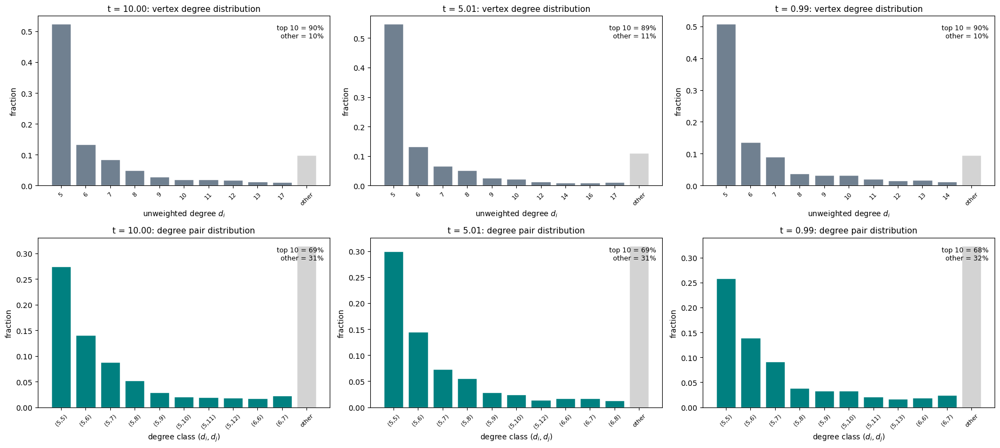

In [8]:
def plot_degree_distributions(times=TIMES, n_top=10, save_fig_path=None):
    """Vertex-degree (top) and vertex-pair degree-class (bottom) distributions per snapshot.

    Fractions rather than counts, so the rows are comparable across snapshots, with everything
    beyond the `n_top` most frequent values merged into a single trailing bar.
    """
    fig, axes = plt.subplots(2, len(times), figsize=(6.2 * len(times), 8.4))
    axes = np.atleast_2d(axes)

    for col, t_target in enumerate(times):
        s = snaps[t_target]
        deg = s["deg_u"]
        pairs = np.stack([np.minimum(deg[IU], deg[JU]), np.maximum(deg[IU], deg[JU])], axis=1)

        for row, (values, colour, name, xlabel) in enumerate((
                (deg, "slategray", "vertex degree", "unweighted degree $d_i$"),
                (pairs, "teal", "degree pair", r"degree class $(d_i, d_j)$"))):
            vals, frac, other = top_classes(values, n_top)
            labels = ([str(v) for v in vals] if vals.ndim == 1
                      else [f"({a},{b})" for a, b in vals]) + [f"other"]
            ax = axes[row, col]
            ax.bar(np.arange(len(labels)), np.append(frac, other),
                   color=[colour] * len(frac) + ["lightgray"], edgecolor="white")
            ax.set_xticks(np.arange(len(labels)))
            ax.set_xticklabels(labels, rotation=45, fontsize=8)
            ax.set_xlabel(xlabel)
            ax.set_ylabel("fraction")
            ax.set_title(f"t = {s['t']:.2f}: {name} distribution", fontsize=11)
            ax.text(0.98, 0.95, f"top {n_top} = {1 - other:.0%}\nother = {other:.0%}",
                    transform=ax.transAxes, ha="right", va="top", fontsize=9)

    fig.tight_layout()
    if save_fig_path:
        Path(save_fig_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_fig_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_degree_distributions(save_fig_path="figs/ctd_degree_distributions.png")

## 3. The CTD distribution against the degree classes

Top row: the raw CTD distribution with the most populated degree classes drawn as overlapping
transparent histograms on top of the full distribution, so where classes bleed into each other is
visible. The comb is only resolvable for the first few classes: the spacing between classes
follows $1/d_i + 1/d_j$ and shrinks faster than the classes' own width, so beyond roughly
$(5,8)$ they merge into the smooth shoulder.

Bottom row: the measured CTD of every pair against its theoretical value
$\mathrm{vol}(G)\,(1/d_i + 1/d_j)$, coloured by whether the pair is within- or between-cluster.
The dashed diagonal is the theory with its own constant -- no fit, no rescaling. In the noise
stage both populations sit on one line slightly above the diagonal; after speciation the
within-cluster pairs stay there and the between-cluster ones lift off it entirely.

The offset above the diagonal is real and systematic, not a normalization choice: the identity
holds when every non-trivial eigenvalue of the normalized Laplacian is 1, and the true CTD
weights each spectral direction by $1/\lambda_k$. The bulk spread of the spectrum makes the mean
of those weights exceed 1, so measured commute times run consistently above the flat-spectrum
prediction.

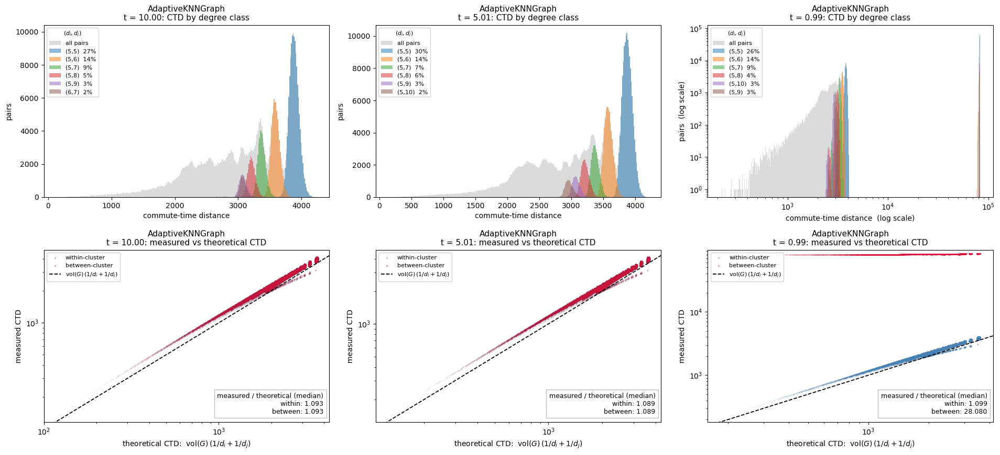

In [9]:
def plot_ctd_vs_degrees(snapshots, times=TIMES, n_classes=6, bins=300, alpha=0.5, log_ratio=10.0,
                        save_fig_path=None):
    """CTD distribution split into degree classes (top) and against its theoretical value (bottom).

    `snapshots` maps a time to a `snapshot`-style dict, so the same figure serves the pipeline's
    graph and the alternative constructions of section 4; pairs are grouped by `deg_class`.

    The bottom row plots the measured CTD against `vol(G) * (1/d_i + 1/d_j)` together with the
    identity line: no regression is performed and the theoretical constant is used as it stands.
    It is log-log throughout, since after speciation the between-cluster commute times run more
    than an order of magnitude above the within-cluster ones.

    The top row keeps a linear axis while the snapshot's CTDs span less than `log_ratio` (p99/p1)
    and switches to a logarithmic one when they span more -- linear resolves the comb of degree
    peaks, but at `t = 1` the two cluster populations are a factor ~60 apart and a linear axis
    collapses each of them into a spike. Those panels get a logarithmic count axis as well,
    otherwise the very tight between-cluster population dwarfs everything else.
    """
    fig, axes = plt.subplots(2, len(times), figsize=(6.4 * len(times), 8.8))
    axes = np.atleast_2d(axes)
    palette = plt.get_cmap("tab10")

    for col, t_target in enumerate(times):
        s = snapshots[t_target]
        c, between = s["ctd"], s["between"]
        deg = s["deg_class"]
        pairs = np.stack([np.minimum(deg[IU], deg[JU]), np.maximum(deg[IU], deg[JU])], axis=1)
        classes, counts = np.unique(pairs, axis=0, return_counts=True)
        top = classes[np.argsort(counts)[::-1][:n_classes]]

        ax = axes[0, col]
        p1, p99 = np.percentile(c, [1, 99])
        use_log = p99 / p1 > log_ratio
        edges = (np.logspace(np.log10(c.min()), np.log10(c.max()), 3 * bins) if use_log
                 else np.linspace(c.min(), c.max(), bins))
        ax.hist(c, bins=edges, color="0.86", label="all pairs")
        for n, (a, b) in enumerate(top):
            m = (pairs[:, 0] == a) & (pairs[:, 1] == b)
            ax.hist(c[m], bins=edges, color=palette(n), alpha=alpha,
                    label=f"({a},{b})  {m.mean():.0%}")
        if use_log:
            ax.set_xscale("log")
            ax.set_yscale("log")
        ax.set_xlabel("commute-time distance" + ("  (log scale)" if use_log else ""))
        ax.set_ylabel("pairs" + ("  (log scale)" if use_log else ""))
        ax.set_title(f"{s['graph']}\nt = {s['t']:.2f}: CTD by degree class", fontsize=11)
        ax.legend(fontsize=8, title=s["class_title"], title_fontsize=8, loc="upper left",
                  framealpha=0.85)

        ax = axes[1, col]
        pred = theoretical_ctd(s)
        for m, colour, name in ((~between, "steelblue", "within-cluster"),
                                (between, "crimson", "between-cluster")):
            ax.scatter(pred[m], c[m], s=2, c=colour, alpha=0.05, linewidths=0,
                       rasterized=True, label=name)
        span = [min(pred.min(), c.min()) * 0.85, max(pred.max(), c.max()) * 1.15]
        ax.plot(span, span, "k--", lw=1.3, label=r"$\mathrm{vol}(G)\,(1/d_i + 1/d_j)$")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(pred.min() * 0.85, pred.max() * 1.15)
        ax.set_ylim(c.min() * 0.85, c.max() * 1.15)
        ax.set_xlabel(r"theoretical CTD:  $\mathrm{vol}(G)\,(1/d_i + 1/d_j)$")
        ax.set_ylabel("measured CTD")
        ax.set_title(f"{s['graph']}\nt = {s['t']:.2f}: measured vs theoretical CTD", fontsize=11)
        leg = ax.legend(fontsize=8, loc="upper left", framealpha=0.85)
        for handle in leg.legend_handles:
            handle.set_alpha(1.0)
        ax.text(0.98, 0.04,
                f"measured / theoretical (median)\n"
                f"within: {np.median(c[~between] / pred[~between]):.3f}\n"
                f"between: {np.median(c[between] / pred[between]):.3f}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
                bbox=dict(fc="white", alpha=0.85, ec="0.7"))

    fig.tight_layout()
    if save_fig_path:
        Path(save_fig_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_fig_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_ctd_vs_degrees(snaps, save_fig_path="figs/ctd_vs_degree_classes.png")

## 4. Other graph constructions

Is the degree law a quirk of `AdaptiveKNNGraph`, or does every similarity graph fall into it?
Each subsection below builds a different graph on the **same samples** of the same three
snapshots, computes its commute times with the pipeline's own `ctd_matrix` (unnormalized
Laplacian, as in `CTDs.jbl`), and draws the section-3 figure for it -- CTD split by degree class
on top, measured against $\mathrm{vol}(G)\,(1/d_i + 1/d_j)$ underneath, with no fitted constant.

`ctd_matrix` needs a connected graph, and after speciation the two clusters are far enough apart
that sparse constructions split along them. The sparse graphs therefore take the union with the
Euclidean minimum spanning tree, which adds the fewest and shortest edges that connect the graph
-- at `t = 1` that is a single between-cluster bridge, the same role `connect_components` plays
in the pipeline. Mutual kNN is deferred to section 5: at these `k` it shatters into hundreds of
components in the noise stage, and gluing those together with the MST makes it mostly a tree.

**Notation.** $x_1, \dots, x_N$ are the samples of one snapshot, $r_{ij} = \lVert x_i - x_j \rVert$,
$N_k(i)$ is the set of the $k$ points nearest to $x_i$ (excluding $i$ itself), and $\mathcal{T}$ is
the edge set of the Euclidean minimum spanning tree, i.e. the MST of the complete graph with edge
lengths $r_{ij}$. Every graph is undirected with $W_{ii} = 0$; degrees and volume are always the
weighted ones, $d_i = \sum_j W_{ij}$ and $\mathrm{vol}(G) = \sum_i d_i$.

The sparse graphs are binary. Section 1 showed the Gaussian weights on kNN edges are
near-constant in this dimension, and a constant weight cancels out of the commute time, so
binary weights lose nothing. Dense graphs have continuous degrees, so their pairs are grouped by
the **sextile** of the weighted degree instead of by an integer degree: vertex $i$ gets class
$c_i = q$ when $d_i$ lies in the $q$-th sextile of $\{d_1, \dots, d_N\}$, $q = 1, \dots, 6$, and a
pair is classed by $(\min(c_i, c_j), \max(c_i, c_j))$. This applies to 4b-4d.

In [10]:
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.spatial.distance import squareform

from lib.distances import ctd_matrix

DISTS = {t: squareform(pdist(s["points"])) for t, s in snaps.items()}


def mst_adjacency(R):
    """Symmetric boolean adjacency of the Euclidean minimum spanning tree of distance matrix `R`."""
    tree = minimum_spanning_tree(R).toarray() > 0
    return tree | tree.T


def knn_mst_graph(R, k):
    """Binary symmetric kNN graph (`i ~ j` if either is among the other's `k` nearest), plus the MST."""
    n = len(R)
    nearest = np.argsort(R, axis=1)[:, 1:k + 1]
    A = np.zeros((n, n), dtype=bool)
    A[np.arange(n)[:, None], nearest] = True
    return (A | A.T | mst_adjacency(R)).astype(float)


def eps_graph(R):
    """Binary epsilon-graph at the connectivity threshold: `eps` is the longest MST edge."""
    eps = minimum_spanning_tree(R).data.max()
    A = R <= eps
    np.fill_diagonal(A, False)
    return A.astype(float)


def full_gaussian_graph(R, scale):
    """Complete graph with weights `exp(-r^2 / 2 sigma^2)`, `sigma = scale * median pairwise distance`."""
    sigma = scale * np.median(R[IU, JU])
    W = np.exp(-R ** 2 / (2 * sigma ** 2))
    np.fill_diagonal(W, 0.0)
    return W


def graph_snapshots(build, graph, n_deg_bins=None):
    """Section-3 snapshot dicts for the graph `build(R)` makes from each snapshot's distances.

    Positions, times and cluster labels are shared with `snaps`; the graph, its CTDs and its
    degrees are replaced. With `n_deg_bins` the pairs are classed by quantile bin of the weighted
    degree, otherwise by the unweighted degree.
    """
    out = {}
    for t, s in snaps.items():
        W = build(DISTS[t])
        deg_u, deg_w = (W > 0).sum(1), W.sum(1)
        if n_deg_bins is None:
            deg_class, class_title = deg_u, "$(d_i, d_j)$"
        else:
            cuts = np.quantile(deg_w, np.linspace(0, 1, n_deg_bins + 1)[1:-1])
            deg_class, class_title = np.digitize(deg_w, cuts) + 1, "degree sextiles"
        out[t] = {**s, "W": W, "ctd": ctd_matrix(W)[IU, JU], "deg_u": deg_u, "deg_w": deg_w,
                  "vol": W.sum(), "deg_class": deg_class, "class_title": class_title,
                  "graph": graph}
        print(f"{graph:>28}  t={s['t']:5.2f}  edges={int((W > 0).sum() // 2):6d}  "
              f"degree {deg_u.min()}-{deg_u.max()}  CTD cv {out[t]['ctd'].std() / out[t]['ctd'].mean():.3f}")
    return out

### 4a. Plain symmetric kNN, `k = 15`

$$W_{ij} = \mathbb{1}\big[\, j \in N_k(i) \;\lor\; i \in N_k(j) \;\lor\; \{i,j\} \in \mathcal{T} \,\big],
\qquad k = 15.$$

$i \sim j$ when either is among the other's 15 nearest neighbours -- the textbook kNN graph,
without `AdaptiveKNNGraph`'s per-component refinement to a smaller `k`, plus the MST for
connectivity. Larger `k` than the pipeline's effective 5, so the degrees are higher and the
classes more numerous and closer together; the hub skew is the same high-dimensional effect.

         symmetric kNN, k=15  t=10.00  edges= 12944  degree 15-313  CTD cv 0.235
         symmetric kNN, k=15  t= 5.01  edges= 13027  degree 15-273  CTD cv 0.236
         symmetric kNN, k=15  t= 0.99  edges= 12549  degree 15-206  CTD cv 0.835


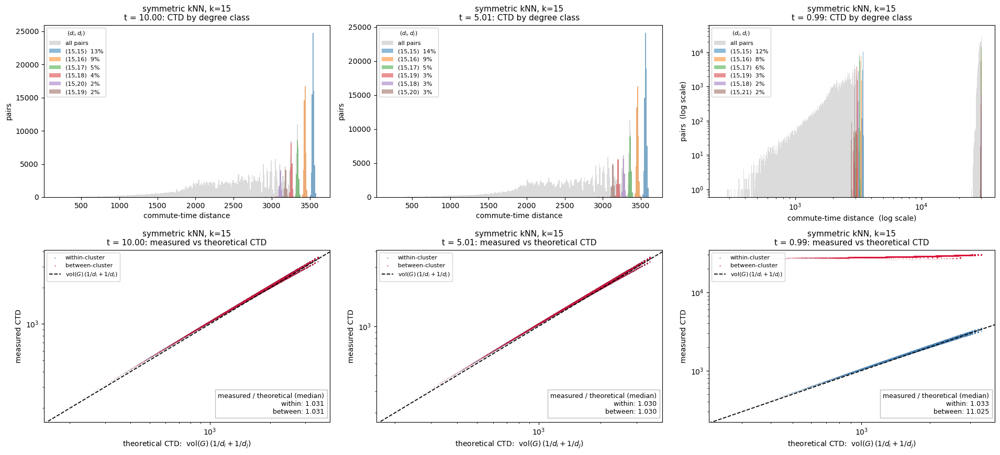

In [11]:
snaps_knn = graph_snapshots(lambda R: knn_mst_graph(R, k=15), "symmetric kNN, k=15")
plot_ctd_vs_degrees(snaps_knn, save_fig_path="figs/ctd_vs_degree_classes_knn15.png")

### 4b. Epsilon-graph at the connectivity threshold

$$W_{ij} = \mathbb{1}\big[\, r_{ij} \le \varepsilon \,\big], \qquad
\varepsilon = \max_{\{i,j\} \in \mathcal{T}} r_{ij}.$$

Every MST edge is no longer than $\varepsilon$, so $\mathcal{T} \subseteq G$ and the graph is
connected without any explicit union.

$i \sim j$ when $\lVert x_i - x_j \rVert \le \varepsilon$, with $\varepsilon$ the longest edge
of the Euclidean MST -- the smallest radius at which the graph is connected, so no extra bridging
is needed. Unlike kNN the degree is not floored at `k`: it is the number of points inside the
ball. In high dimension the threshold is set by the single most isolated point, so the
noise-stage graph is dense (~85k edges) and its degrees run from 1 to ~730 -- far too many
distinct values for integer classes, so pairs are grouped by weighted-degree sextile as for the
dense graphs. At `t = 1` the threshold is set by the between-cluster gap, which is much larger
than the within-cluster distances, so each cluster becomes nearly complete.

epsilon-graph, eps = max MST edge  t=10.00  edges= 84201  degree 1-730  CTD cv 2.271
epsilon-graph, eps = max MST edge  t= 5.01  edges= 88601  degree 1-728  CTD cv 1.902
epsilon-graph, eps = max MST edge  t= 0.99  edges=250030  degree 476-523  CTD cv 0.993


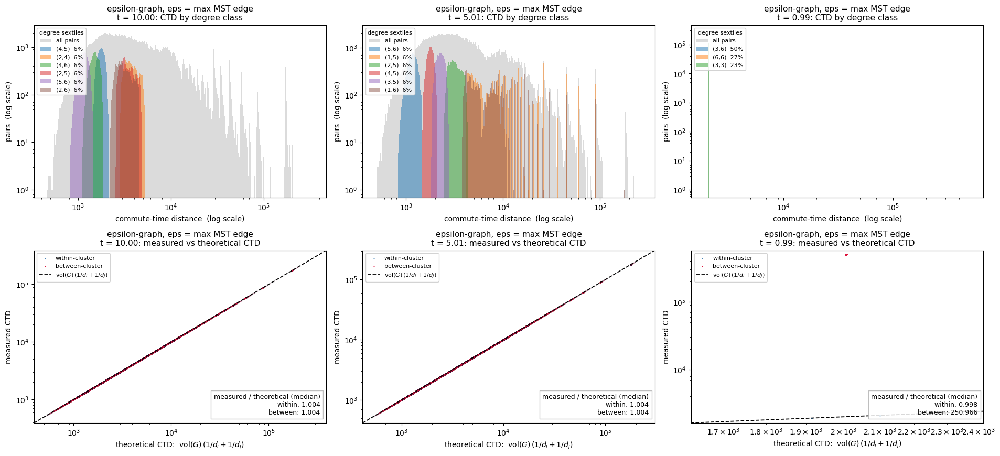

In [12]:
snaps_eps = graph_snapshots(eps_graph, "epsilon-graph", n_deg_bins=6)
for t, s in snaps_eps.items():
    s["graph"] = rf"epsilon-graph, $\varepsilon$ = {DISTS[t][s['W'] > 0].max():.2f}"
plot_ctd_vs_degrees(snaps_eps, save_fig_path="figs/ctd_vs_degree_classes_eps.png")

### 4c. Fully connected Gaussian kernel, $\sigma$ = median distance

$$W_{ij} = \exp\!\left(-\frac{r_{ij}^2}{2\sigma^2}\right) \;\; (i \ne j), \qquad
\sigma = s \cdot \operatorname{median}_{i<j} r_{ij}, \quad s = 1.$$

Every pair is an edge with weight $\exp(-r^2 / 2\sigma^2)$, $\sigma$ the median pairwise
distance. In the noise stage all distances concentrate around $\sigma$, so all weights sit near
$e^{-1/2}$ and the weighted degrees are nearly equal: there is no comb, because there are no
discrete degree classes -- but the degree law then predicts an almost constant commute time,
and that is what comes out. With a kernel this wide the cut never becomes weak: even at `t = 1`
the between-cluster pairs stay on the degree law.

full Gaussian, sigma = median  t=10.00  edges=499500  degree 999-999  CTD cv 0.008
full Gaussian, sigma = median  t= 5.01  edges=499500  degree 999-999  CTD cv 0.008
full Gaussian, sigma = median  t= 0.99  edges=499500  degree 999-999  CTD cv 0.026


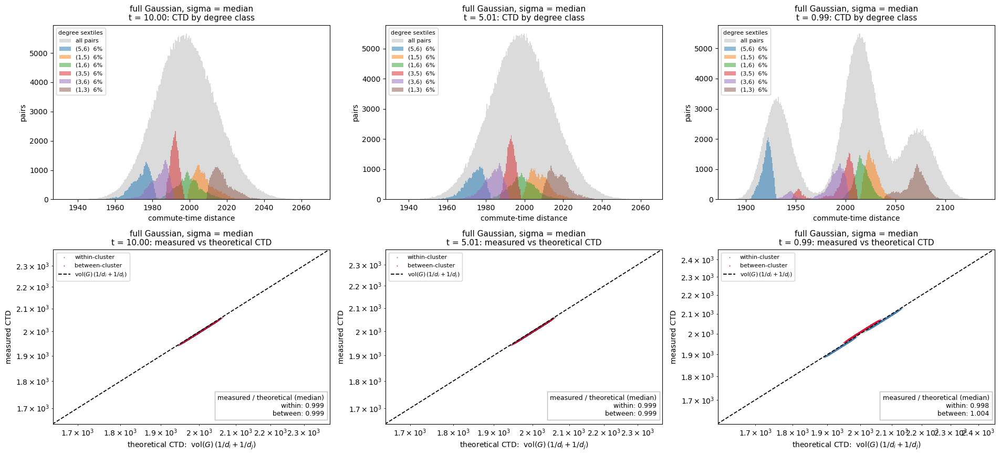

In [13]:
snaps_full = graph_snapshots(lambda R: full_gaussian_graph(R, 1.0), "full Gaussian, sigma = median",
                             n_deg_bins=6)
plot_ctd_vs_degrees(snaps_full, save_fig_path="figs/ctd_vs_degree_classes_full_gauss.png")

### 4d. Fully connected Gaussian kernel, $\sigma$ = 0.3 × median distance

The 4c graph with $s = 0.3$.

The same complete graph with a narrower kernel, so the weights are local again: neighbours dominate
each row and distant pairs contribute little. The noise stage is still governed by degrees, but
after speciation the between-cluster weights become tiny compared with the within-cluster ones, so
the cut is weak and the between-cluster commute times should rise far above the degree law.

full Gaussian, sigma = 0.3 median  t=10.00  edges=499500  degree 999-999  CTD cv 0.090
full Gaussian, sigma = 0.3 median  t= 5.01  edges=499500  degree 999-999  CTD cv 0.089
full Gaussian, sigma = 0.3 median  t= 0.99  edges=499500  degree 999-999  CTD cv 1.001


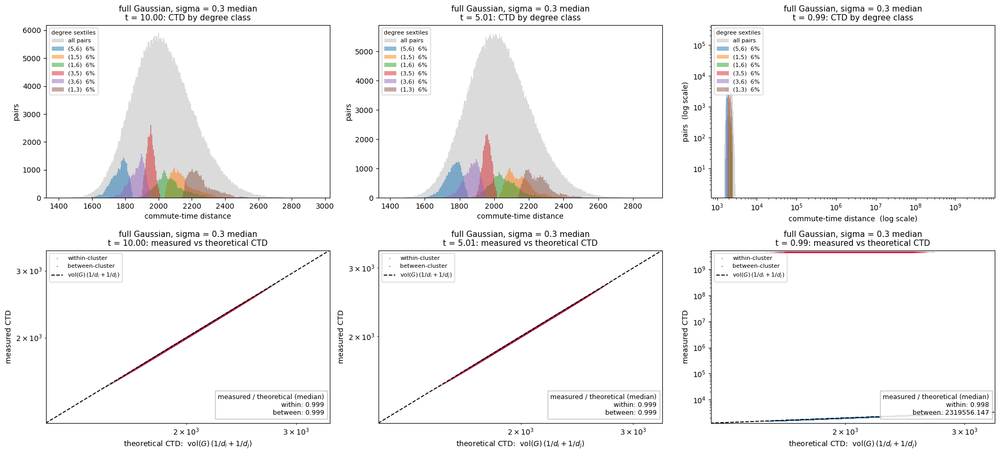

In [14]:
snaps_local = graph_snapshots(lambda R: full_gaussian_graph(R, 0.3), "full Gaussian, sigma = 0.3 median",
                              n_deg_bins=6)
plot_ctd_vs_degrees(snaps_local, save_fig_path="figs/ctd_vs_degree_classes_local_gauss.png")

## 5. Graphs outside the von Luxburg regime

Section 4 says every construction tried so far lands on the degree law in the noise stage. That
is what von Luxburg et al. predict: their bound is roughly

$$\left| \frac{\mathrm{CTD}(i,j)}{\mathrm{vol}(G)} - \left(\frac{1}{d_i} + \frac{1}{d_j}\right) \right|
\;\lesssim\; \left(\frac{1}{\lambda_2} + 2\right) \frac{w_{\max}}{d_{\min}^2},$$

with $\lambda_2$ the spectral gap of the normalized Laplacian. Isotropic noise in $D = 1024$ has no
low-dimensional structure, so any graph that follows its neighbourhoods is an expander -- large
$\lambda_2$ -- unless it is close to a tree. The graphs here are the sparse, topology-preserving
ones that get there: a small minimum degree and, in the noise stage, a small spectral gap. All are
binary, use the notation of section 4, and are connected by construction or by the MST union.

In [16]:
def k_mst_graph(R, k):
    """Binary union of `k` successive edge-disjoint Euclidean MSTs.

    Each round removes the previous trees' edges from the complete graph before taking its MST;
    `minimum_spanning_tree` reads a zero entry as a missing edge.
    """
    R = R.copy()
    A = np.zeros(R.shape, dtype=bool)
    for _ in range(k):
        tree = mst_adjacency(R)
        A |= tree
        R[tree] = 0.0
    return A.astype(float)


def mutual_knn_mst_graph(R, k):
    """Binary mutual kNN graph (`i ~ j` only if each is among the other's `k` nearest), plus the MST."""
    n = len(R)
    nearest = np.argsort(R, axis=1)[:, 1:k + 1]
    A = np.zeros((n, n), dtype=bool)
    A[np.arange(n)[:, None], nearest] = True
    return ((A & A.T) | mst_adjacency(R)).astype(float)

### 5a. Euclidean minimum spanning tree

$$W_{ij} = \mathbb{1}\big[\, \{i,j\} \in \mathcal{T} \,\big].$$

The extreme case: $N - 1$ edges, $d_{\min} = 1$, $\lambda_2 \sim 10^{-3}$. On a tree the effective
resistance between two vertices is the number of edges on the path joining them, so the commute
time is exactly $\mathrm{CTD}(i,j) = 2(N-1)\,\mathrm{hops}(i,j)$ -- pure path length, with no degree
term at all. In the noise stage that path length is a property of a random spanning tree of the
noise rather than of any geometry, so the CTD distribution is that of tree distances.

               Euclidean MST  t=10.00  edges=   999  degree 1-49  CTD cv 0.357
               Euclidean MST  t= 5.01  edges=   999  degree 1-54  CTD cv 0.421
               Euclidean MST  t= 0.99  edges=   999  degree 1-32  CTD cv 0.466


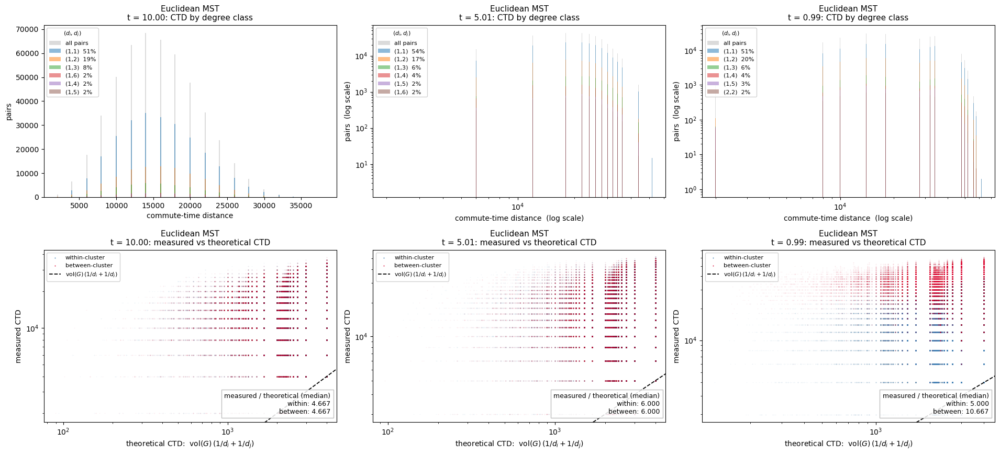

In [17]:
snaps_mst = graph_snapshots(lambda R: k_mst_graph(R, 1), "Euclidean MST")
plot_ctd_vs_degrees(snaps_mst, save_fig_path="figs/ctd_vs_degree_classes_mst.png")

### 5b. Mutual kNN plus the MST

$$W_{ij} = \mathbb{1}\big[\, \big(j \in N_k(i) \,\land\, i \in N_k(j)\big) \;\lor\; \{i,j\} \in \mathcal{T} \,\big].$$

Mutual kNN keeps an edge only when both endpoints choose it, so the high-dimensional hubs --
points many others pick but which pick only `k` of them back -- lose most of their edges. In the
noise stage that leaves many small components, and the MST edges that join them are long chains,
so the graph is tree-like at small `k` ($\lambda_2 \approx 0.03$ at `k = 5`) and drifts back toward
an expander as `k` grows ($\lambda_2 \approx 0.2$ at `k = 15`). The minimum degree stays 1 at every
`k`, since a point nobody picks back keeps only its MST edge.

      mutual kNN, k=5, + MST  t=10.00  edges=  1217  degree 1-52  CTD cv 0.318
      mutual kNN, k=5, + MST  t= 5.01  edges=  1211  degree 1-54  CTD cv 0.313
      mutual kNN, k=5, + MST  t= 0.99  edges=  1280  degree 1-33  CTD cv 0.458


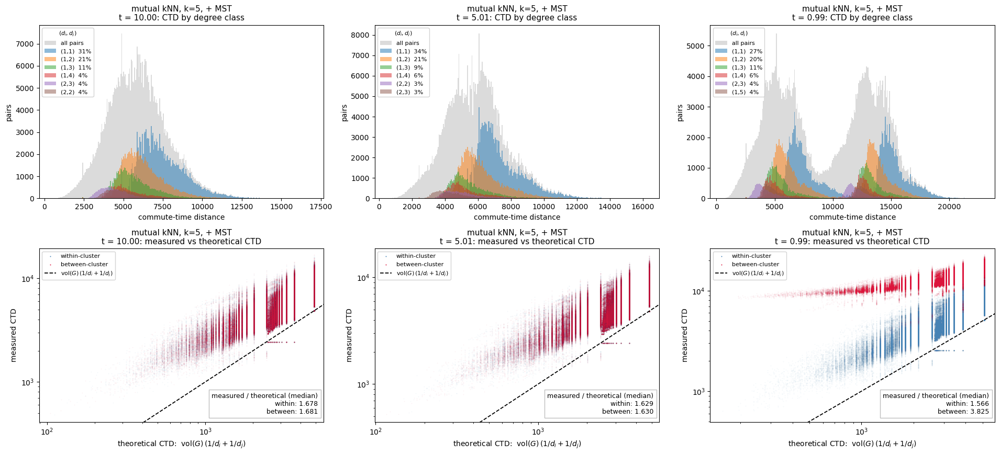

     mutual kNN, k=15, + MST  t=10.00  edges=  2536  degree 1-58  CTD cv 0.536
     mutual kNN, k=15, + MST  t= 5.01  edges=  2464  degree 1-57  CTD cv 0.518
     mutual kNN, k=15, + MST  t= 0.99  edges=  2843  degree 1-37  CTD cv 0.533


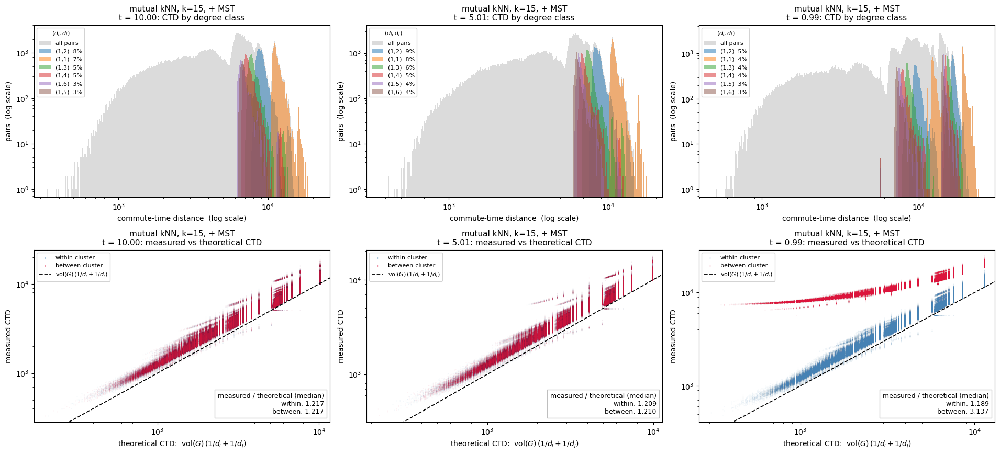

In [18]:
MUTUAL_KS = (5, 15)

snaps_mutual = {}
for k in MUTUAL_KS:
    snaps_mutual[k] = graph_snapshots(lambda R: mutual_knn_mst_graph(R, k), f"mutual kNN, k={k}, + MST")
    plot_ctd_vs_degrees(snaps_mutual[k], save_fig_path=f"figs/ctd_vs_degree_classes_mutual_knn{k}.png")

### 5c. 5-MST

$$W_{ij} = \mathbb{1}\Big[\, \{i,j\} \in \textstyle\bigcup_{m=1}^{5} \mathcal{T}_m \,\Big],$$

where $\mathcal{T}_1 = \mathcal{T}$ and $\mathcal{T}_m$ is the MST of the complete graph with the
edges of $\mathcal{T}_1, \dots, \mathcal{T}_{m-1}$ removed (Carreira-Perpiñán & Zemel's perturbed
MSTs, here in their plain disjoint-union form). Each tree contributes one edge to every vertex,
so $d_{\min} = 5$ by construction, like the pipeline's $k = 5$ graph -- but the edges follow
successive spanning trees rather than nearest-neighbour lists. That minimum degree is already
enough to restore the degree law ($\lambda_2 \approx 0.43$ in the noise stage); it is included as the
dense end of the k-MST family next to the tree in 5a.

                       5-MST  t=10.00  edges=  4995  degree 5-178  CTD cv 0.253
                       5-MST  t= 5.01  edges=  4995  degree 5-167  CTD cv 0.253
                       5-MST  t= 0.99  edges=  4995  degree 5-121  CTD cv 0.342


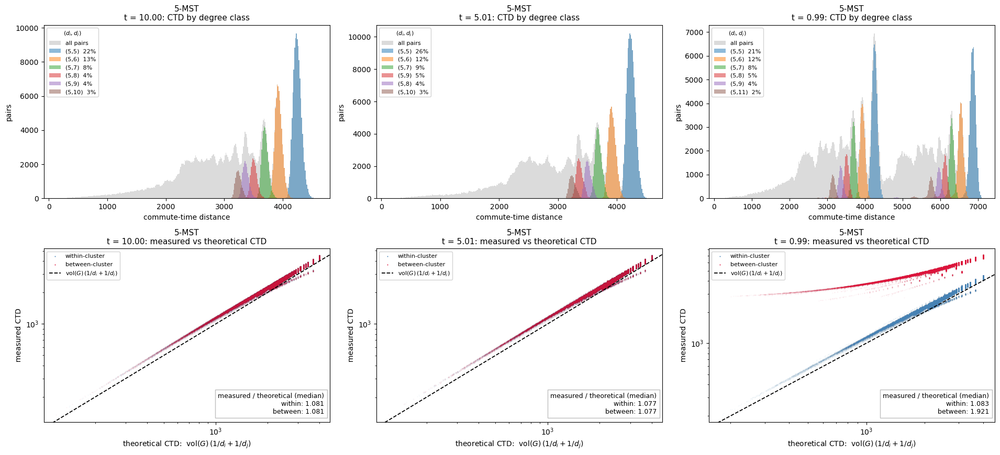

In [19]:
snaps_kmst = graph_snapshots(lambda R: k_mst_graph(R, 5), "5-MST")
plot_ctd_vs_degrees(snaps_kmst, save_fig_path="figs/ctd_vs_degree_classes_5mst.png")